In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from sqlalchemy import create_engine

In [2]:
engine = create_engine(
    "mysql+pymysql://root@localhost:3306/climate_watch"
)

df_city = pd.read_sql("SELECT * FROM GlobalLandTemperaturesByCity", con=engine, parse_dates=["dt"])
df_city["year"] = df_city["dt"].dt.year
df_city["month"] = df_city["dt"].dt.month

df_unique_city_id = df_city[["City", "Country", "Latitude", "Longitude"]].drop_duplicates().reset_index(drop=True).reset_index(names="city_id")

df_city = df_city.merge(df_unique_city_id, how="left")
df_city_sorted = df_city.sort_values(["city_id", "dt"])

In [205]:
# Biggest fluctiations per month
df_city_sorted["temp_next_month"] = df_city_sorted.groupby(["city_id"])["AverageTemperature"].shift(-1)
df_city_sorted["temp_diff_month"] = df_city_sorted["temp_next_month"] - df_city_sorted["AverageTemperature"]

greatest_negative_fluctuation_serie = df_city_sorted[df_city_sorted["temp_diff_month"] == df_city_sorted["temp_diff_month"].min()].iloc[0]
neg_start_date = greatest_negative_fluctuation_serie["dt"] - pd.DateOffset(months=12)
neg_end_date = greatest_negative_fluctuation_serie["dt"] + pd.DateOffset(months=12)
df_neg_city_monthly = df_city_sorted[
    (df_city_sorted["city_id"] == greatest_negative_fluctuation_serie["city_id"])
    & (df_city_sorted["dt"] > neg_start_date)
    & (df_city_sorted["dt"] < neg_end_date)
    ].reset_index(drop=True)

greatest_positive_fluctuation_serie = df_city_sorted[df_city_sorted["temp_diff_month"] == df_city_sorted["temp_diff_month"].max()].iloc[0]
pos_start_date = greatest_positive_fluctuation_serie["dt"] - pd.DateOffset(months=12)
pos_end_date = greatest_positive_fluctuation_serie["dt"] + pd.DateOffset(months=12)
df_pos_city_monthly = df_city_sorted[
    (df_city_sorted["city_id"] == greatest_positive_fluctuation_serie["city_id"])
    & (df_city_sorted["dt"] > pos_start_date)
    & (df_city_sorted["dt"] < pos_end_date)
    ].reset_index(drop=True)



# Biggest fluctiations per year
df_city_grouped_year = df_city_sorted.groupby(["city_id", "year"]).agg({
        "AverageTemperature": "mean",
        "City": "first",
        "Country": "first",
        "dt": "first"
    }).reset_index("city_id")
df_city_grouped_year["temp_next_year"] = df_city_grouped_year.groupby(["city_id"])["AverageTemperature"].shift(-1)
df_city_grouped_year["temp_diff_year"] = df_city_grouped_year["temp_next_year"] - df_city_grouped_year["AverageTemperature"]

greatest_negative_fluctuation_serie = df_city_grouped_year[df_city_grouped_year["temp_diff_year"] == df_city_grouped_year["temp_diff_year"].min()].iloc[0]
neg_start_date = greatest_negative_fluctuation_serie["dt"] - pd.DateOffset(years=12)
neg_end_date = greatest_negative_fluctuation_serie["dt"] + pd.DateOffset(years=12)
df_neg_city_yearly = df_city_grouped_year[
    (df_city_grouped_year["city_id"] == greatest_negative_fluctuation_serie["city_id"])
    & (df_city_grouped_year["dt"] > neg_start_date)
    & (df_city_grouped_year["dt"] < neg_end_date)
    ].reset_index(drop=True)

greatest_positive_fluctuation_serie = df_city_grouped_year[df_city_grouped_year["temp_diff_year"] == df_city_grouped_year["temp_diff_year"].max()].iloc[0]
pos_start_date = greatest_positive_fluctuation_serie["dt"] - pd.DateOffset(years=12)
pos_end_date = greatest_positive_fluctuation_serie["dt"] + pd.DateOffset(years=12)
df_pos_city_yearly = df_city_grouped_year[
    (df_city_grouped_year["city_id"] == greatest_positive_fluctuation_serie["city_id"])
    & (df_city_grouped_year["dt"] > pos_start_date)
    & (df_city_grouped_year["dt"] < pos_end_date)
    ].reset_index(drop=True)

In [255]:
test_avg

np.timedelta64(31536000,'s')

In [258]:
maximum_x

Timestamp('1816-01-01 00:00:00')

Timestamp('1815-01-01 00:00:00')

In [262]:
avg_x

Timestamp('1917-10-01 00:00:00')

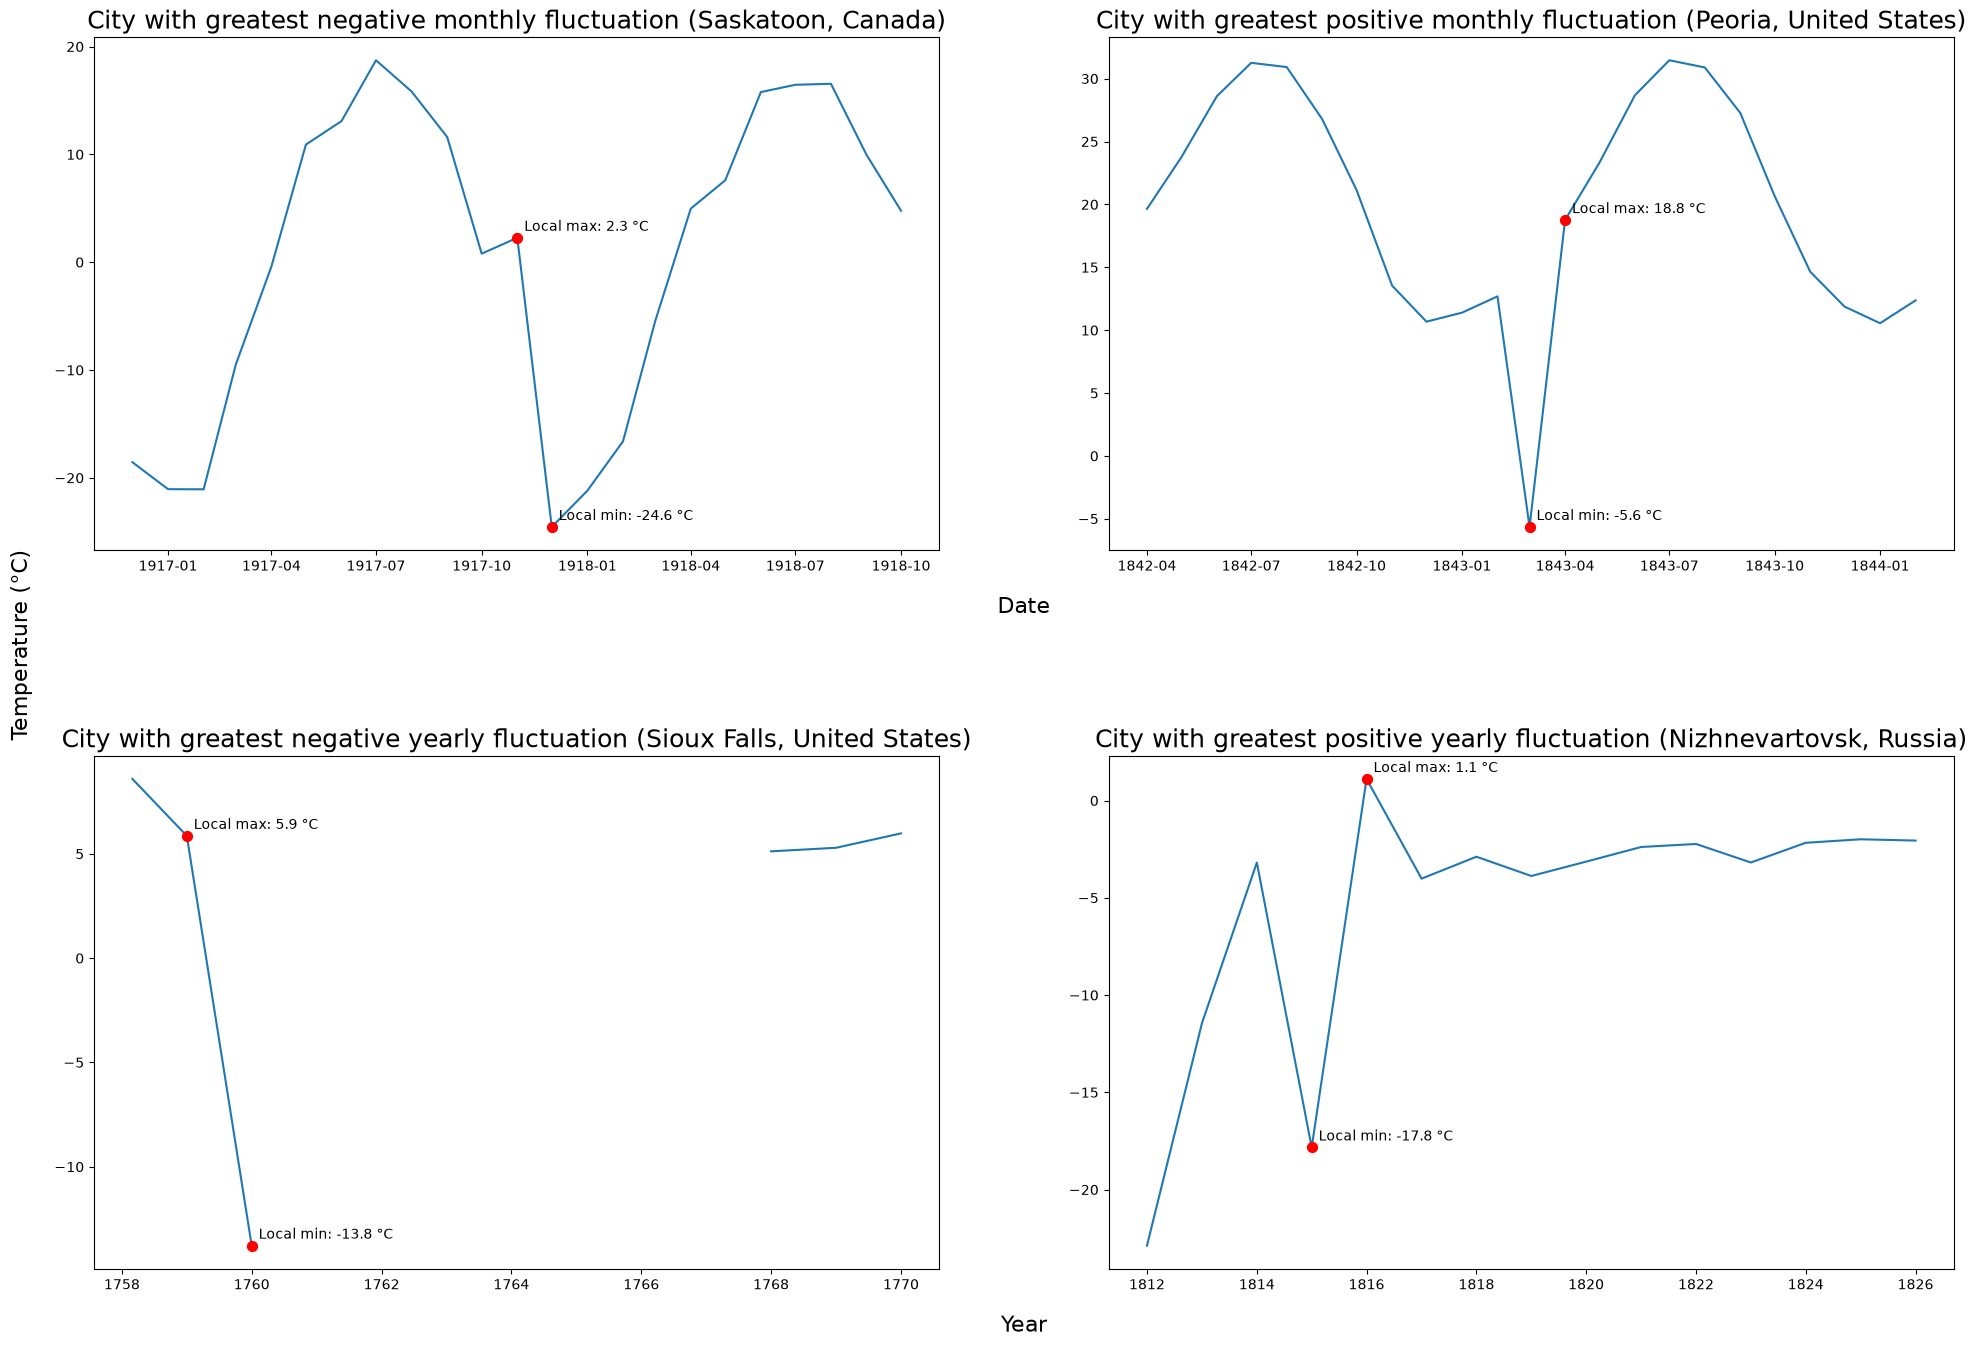

In [271]:
fig, ax = plt.subplots(2,2,figsize=(24,16))
fig.subplots_adjust(hspace=0.4)
fig.supylabel("Temperature (°C)", x=0.09, fontsize=16)

# Plot greatest negative fluctuation between months
ax[0,0].plot(df_neg_city_monthly["dt"], df_neg_city_monthly["AverageTemperature"])
ax[0,0].title.set_text(f"City with greatest negative monthly fluctuation ({
    df_neg_city_monthly["City"].iloc[0]}, {df_neg_city_monthly["Country"].iloc[0]})")
ax[0,0].title.set_size(18)

greatest_fluc_index = df_neg_city_monthly["temp_diff_month"].idxmin()
maximum_x = df_neg_city_monthly.loc[greatest_fluc_index]["dt"]
maximum_y = df_neg_city_monthly.loc[greatest_fluc_index]["AverageTemperature"]
ax[0,0].scatter(maximum_x, maximum_y, color="red", s=50, zorder=5)
ax[0,0].annotate(
    f"Local max: {round(maximum_y,1)} °C",
    xy=(maximum_x, maximum_y),
    xytext=(5, 5),
    textcoords="offset points")

minimum_x = df_neg_city_monthly.loc[greatest_fluc_index+1]["dt"]
minimum_y = df_neg_city_monthly.loc[greatest_fluc_index+1]["AverageTemperature"]
ax[0,0].scatter(minimum_x, minimum_y, color="red", s=50, zorder=5)
ax[0,0].annotate(
    f"Local min: {round(minimum_y,1)} °C",
    xy=(minimum_x, minimum_y),
    xytext=(5, 5),
    textcoords="offset points")


# Plot greatest positive fluctuation between months
ax[0,1].plot(df_pos_city_monthly["dt"], df_pos_city_monthly["AverageTemperature"])
ax[0,1].title.set_text(f"City with greatest positive monthly fluctuation ({
    df_pos_city_monthly["City"].iloc[0]}, {df_pos_city_monthly["Country"].iloc[0]})")
ax[0,1].title.set_size(18)
ax[0,1].set_xlabel("Date", x=-0.1, labelpad=16, fontsize=16)

greatest_fluc_index = df_pos_city_monthly["temp_diff_month"].idxmax()
minimum_x = df_pos_city_monthly.loc[greatest_fluc_index]["dt"]
minimum_y = df_pos_city_monthly.loc[greatest_fluc_index]["AverageTemperature"]
ax[0,1].scatter(minimum_x, minimum_y, color="red", s=50, zorder=5)
ax[0,1].annotate(
    f"Local min: {round(minimum_y,1)} °C",
    xy=(minimum_x, minimum_y),
    xytext=(5, 5),
    textcoords="offset points")

maximum_x = df_pos_city_monthly.loc[greatest_fluc_index+1]["dt"]
maximum_y = df_pos_city_monthly.loc[greatest_fluc_index+1]["AverageTemperature"]
ax[0,1].scatter(maximum_x, maximum_y, color="red", s=50, zorder=5)
ax[0,1].annotate(
    f"Local max: {round(maximum_y,1)} °C",
    xy=(maximum_x, maximum_y),
    xytext=(5, 5),
    textcoords="offset points")


# Plot greatest negative fluctuation between years
ax[1,0].plot(df_neg_city_yearly["dt"], df_neg_city_yearly["AverageTemperature"])
ax[1,0].title.set_text(f"City with greatest negative yearly fluctuation ({
    df_neg_city_yearly["City"].iloc[0]}, {df_neg_city_yearly["Country"].iloc[0]})")
ax[1,0].title.set_size(18)

greatest_fluc_index = df_neg_city_yearly["temp_diff_year"].idxmin()
maximum_x = df_neg_city_yearly.loc[greatest_fluc_index]["dt"]
maximum_y = df_neg_city_yearly.loc[greatest_fluc_index]["AverageTemperature"]
ax[1,0].scatter(maximum_x, maximum_y, color="red", s=50, zorder=5)
ax[1,0].annotate(
    f"Local max: {round(maximum_y,1)} °C",
    xy=(maximum_x, maximum_y),
    xytext=(5, 5),
    textcoords="offset points")

minimum_x = df_neg_city_yearly.loc[greatest_fluc_index+1]["dt"]
minimum_y = df_neg_city_yearly.loc[greatest_fluc_index+1]["AverageTemperature"]
ax[1,0].scatter(minimum_x, minimum_y, color="red", s=50, zorder=5)
ax[1,0].annotate(
    f"Local min: {round(minimum_y,1)} °C",
    xy=(minimum_x, minimum_y),
    xytext=(5, 5),
    textcoords="offset points")


# Plot greatest positive fluctuation between years
ax[1,1].plot(df_pos_city_yearly["dt"], df_pos_city_yearly["AverageTemperature"])
ax[1,1].title.set_text(f"City with greatest positive yearly fluctuation ({
    df_pos_city_yearly["City"].iloc[0]}, {df_pos_city_yearly["Country"].iloc[0]})")
ax[1,1].title.set_size(18)
ax[1,1].set_xlabel("Year", x=-0.1, labelpad=16, fontsize=16)

greatest_fluc_index = df_pos_city_yearly["temp_diff_year"].idxmax()
minimum_x = df_pos_city_yearly.loc[greatest_fluc_index]["dt"]
minimum_y = df_pos_city_yearly.loc[greatest_fluc_index]["AverageTemperature"]
ax[1,1].scatter(minimum_x, minimum_y, color="red", s=50, zorder=5)
ax[1,1].annotate(
    f"Local min: {round(minimum_y,1)} °C",
    xy=(minimum_x, minimum_y),
    xytext=(5, 5),
    textcoords="offset points")

maximum_x = df_pos_city_yearly.loc[greatest_fluc_index+1]["dt"]
maximum_y = df_pos_city_yearly.loc[greatest_fluc_index+1]["AverageTemperature"]
ax[1,1].scatter(maximum_x, maximum_y, color="red", s=50, zorder=5)
ax[1,1].annotate(
    f"Local max: {round(maximum_y,1)} °C",
    xy=(maximum_x, maximum_y),
    xytext=(5, 5),
    textcoords="offset points")


plt.show()